# EDA and Fraud Detection

### Problem Formulation
Due to the private nature of financial data, there is a lack of publicly available datasets that can be used for analysis. In this project, a synthetic dataset, publicly available on Kaggle, generated using a simulator called PaySim is used. The dataset was generated using aggregated metrics from the private dataset of a multinational mobile financial services company.

There are 6362620 transactions, The data set has 11 attributes which include is

- Type of transactions
- Amount transacted
- Customer ID and Recipient ID
- Old and New balance of Customer and Recipient
- Time step of the transaction
- Whether the transaction was fraudulent or not

### Methodology

- **General Overview:** Have a General Overview of the data
- **EDA:** Perform Exploratory Data Analysis(EDA) to gain more clear insights of the data
- **Data Preprocessing:** With the information gained after performing EDA, Preprocess the Data accordingly
- **Model Building:** Once the data is properly cleaned and preprocessed, use this data to build a Machine Learning
- **Model Performance:** Assess the Performance of the Model on the Testing data set
- **Predictions:** Make Predictions on the Testing data set

## Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Download dataset from kaggle

#### Importing required libraries

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(palette="Set2")
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score,average_precision_score, confusion_matrix,
                             average_precision_score, precision_score, recall_score, roc_auc_score, classification_report, roc_curve,auc )
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler


from xgboost import XGBClassifier, plot_importance

import warnings
warnings.filterwarnings("ignore")

#### Loading Dataset

In [ ]:
data=pd.read_csv("/content/drive/MyDrive/ML/DataMining/تمرین هفتم/PS_20174392719_1491204439457_log.csv")
data.shape

(6362620, 11)

#### Viewing Dataframe

In [ ]:
data.tail()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.0,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.0,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.0,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.0,C2080388513,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,C1280323807,850002.52,0.0,C873221189,6510099.11,7360101.63,1,0


#### Checking count of Fraud and Non-Fraud Transactions

In [ ]:
data['isFlaggedFraud'].value_counts()

,count
isFlaggedFraud,
0,6362604
1,16


In [ ]:
data['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


#### Checking for Null values in dataset

In [ ]:
data.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


#### There are no null values in the data

In [ ]:
data.duplicated().sum()

np.int64(0)

#### There are no duplicate values in the data

In [ ]:
print(list(data.columns))

# shape of data
print(f'The dataset has shape {data.shape}')

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
The dataset has shape (6362620, 11)


#### Statistical Summary of the data

In [ ]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


#### Proportion of type of Transactions

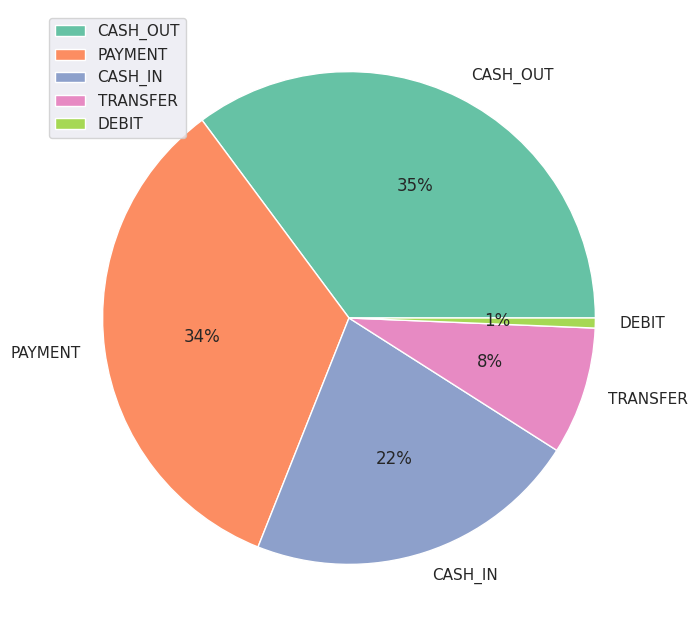

In [ ]:
type = data['type'].value_counts()
transaction = type.index
count = type.values

# drawing piechart
plt.figure(figsize=(8,8))
plt.pie(count, labels=transaction, autopct='%1.0f%%')
plt.legend(loc='upper left')
plt.show()

#### Count of Fraud and Non-Fraud Transactions in each type of Transaction

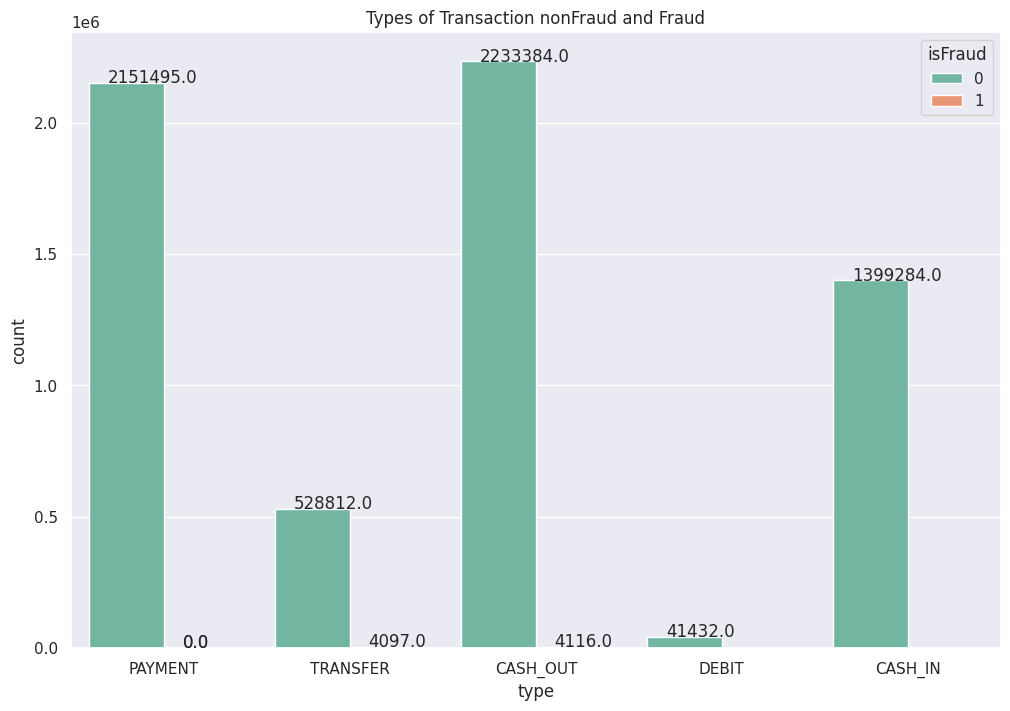

In [ ]:
plt.figure(figsize=(12,8))
ax=sns.countplot(x = "type", hue="isFraud", data = data)
plt.title('Types of Transaction nonFraud and Fraud')
for p in ax.patches:
        ax.annotate('{:.1f}'.format(p.get_height()), (p.get_x()+0.1, p.get_height()+50))

* __Transaction types TRANSFER and CASH_OUT only have FRAUD Transactions.__
* __DEBIT Transactions are only few and TRANSFER type Transactions are also less compared to other type of transactions.__
* __No of Fraud transactions of TRANSFER type are very close to No of CASH_OUT FRAUD transactions. Probably modus operadi of FRAUD transactions is by transferring funds to a specific account and then CASHING OUT from those accounts. We will check this further.__

In [ ]:
data1=data[(data['isFraud']==1) & (data['type']=='TRANSFER')]
data1['nameDest'].value_counts()

,count
nameDest,
C2080388513,1
C435734396,1
C1366804249,1
C625944676,1
C1939028448,1
...,...
C1384210339,1
C1136419747,1
C431687661,1


In [ ]:
data2=data[(data['isFraud']==1) & (data['type']=='CASH_OUT')]
data2['nameOrig'].value_counts()

,count
nameOrig,
C1280323807,1
C840083671,1
C2101527076,1
C1118430673,1
C1597957921,1
...,...
C1499825229,1
C13692003,1
C1275464847,1


There are no specific accounts from which fraud transactions are carried out . Hence we disregard our suspicioun.
So these account name features are not useful for us in modelling as is.

Let's check further

In [ ]:
fraud = data[data["isFraud"] == 1]
valid = data[data["isFraud"] == 0]

In [ ]:
fraud_transfer = fraud[fraud["type"] == "TRANSFER"]
fraud_cashout = fraud[fraud["type"] == "CASH_OUT"]

# checking if the recipient account of a fraudulent transfer was used as a sending account for cashing out
fraud_transfer.nameDest.isin(fraud_cashout.nameOrig).any()

np.False_

For fraudulent transactions, the account that received funds during a transfer was not used at all for cashing out.

We derive a new feature Transaction Type2 from these features account types "C" (customer) and "M" (merchant), which would be the first character for each value under nameOrig and nameDest.

We will create a categorical variable with levels "CC" (Customer to Customer), "CM" (Customer to Merchant), "MC" (Merchant to Customer), "MM" (Merchant to Merchant).

In [ ]:
# adding feature type1
data_new = data.copy() # creating copy of dataset in case I need original dataset
data_new["Type2"] = np.nan # initializing feature column

# filling feature column
data_new.loc[data.nameOrig.str.contains('C') & data.nameDest.str.contains('C'),"Type2"] = "CC"
data_new.loc[data.nameOrig.str.contains('C') & data.nameDest.str.contains('M'),"Type2"] = "CM"
data_new.loc[data.nameOrig.str.contains('M') & data.nameDest.str.contains('C'),"Type2"] = "MC"
data_new.loc[data.nameOrig.str.contains('M') & data.nameDest.str.contains('M'),"Type2"] = "MM"

### Plotting Pairplot

### Visualizing Numeric variables against Fraud using Boxplots.

Text(0.5, 1.0, 'oldbalanceDest vs Fraud')

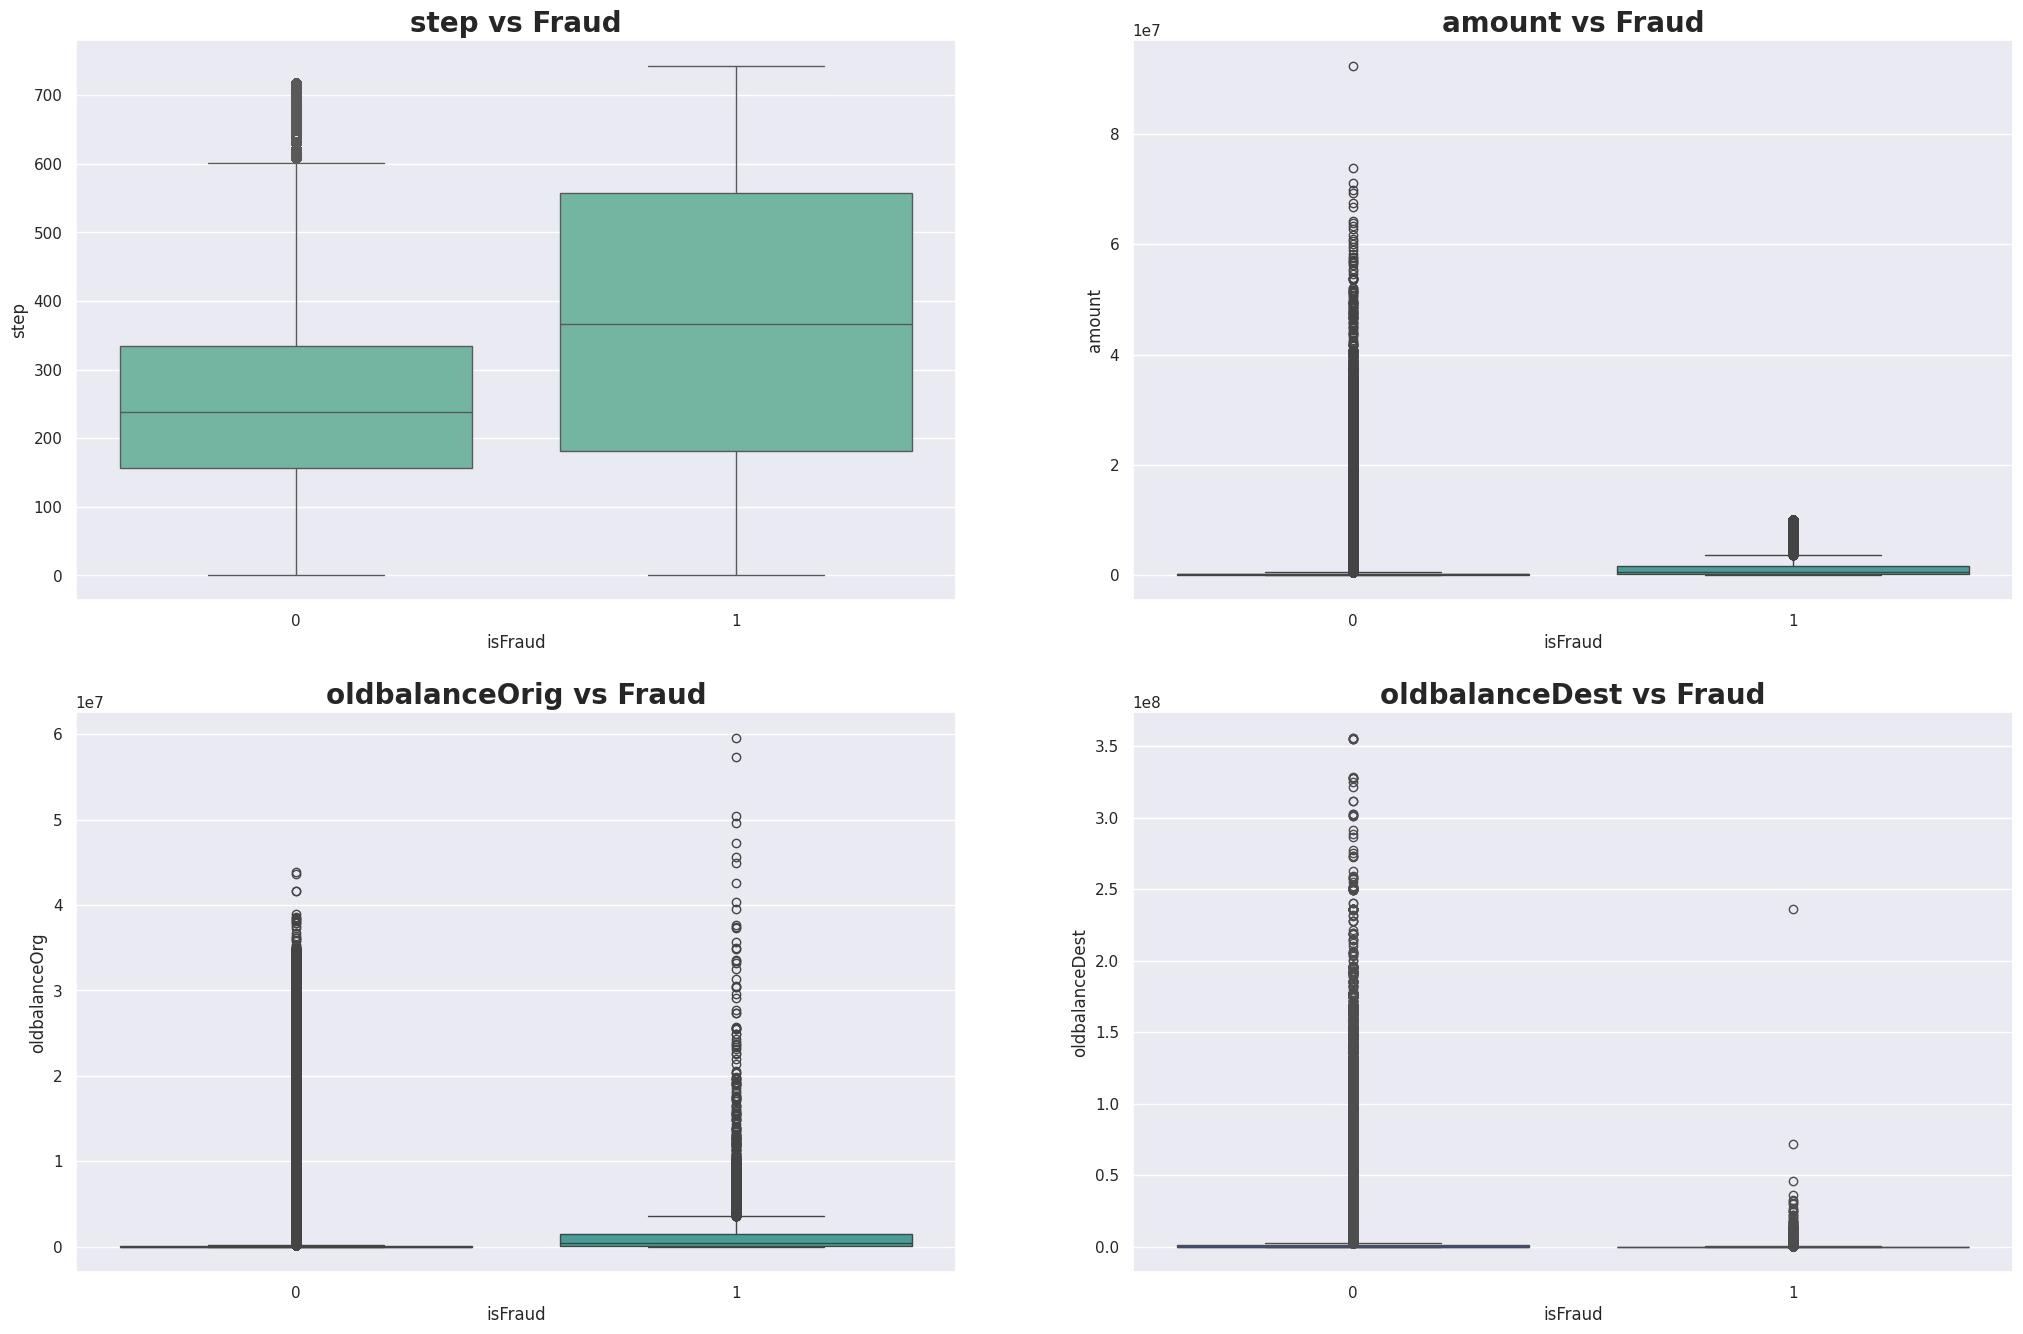

In [ ]:
plt.figure(figsize=(25, 16))
plt.subplot(2,2,1)
sns.boxplot(x = 'isFraud', y = 'step', data = data_new)
plt.title('step vs Fraud',fontweight="bold", size=20)
plt.subplot(2,2,2)
sns.boxplot(x = 'isFraud', y = 'amount', data = data_new,palette="husl")
plt.title('amount vs Fraud',fontweight="bold", size=20)
plt.subplot(2,2,3)
sns.boxplot(x = 'isFraud', y = 'oldbalanceOrg', data = data_new, palette= 'husl')
plt.title('oldbalanceOrig vs Fraud',fontweight="bold", size=20)
plt.subplot(2,2,4)
sns.boxplot(x = 'isFraud', y = 'oldbalanceDest', data = data_new,palette="bright")
plt.title('oldbalanceDest vs Fraud',fontweight="bold", size=20)

- Median amount for fraud transactions is greater than Non Fraud transactions.
- Balance in Origin account in Fraud transactions before transaction is greater than Balance in Origin account of Non Fraud transactions.

In [ ]:
fraud = data_new[data_new["isFraud"] == 1]
valid = data_new[data_new["isFraud"] == 0]

In [ ]:
print("Fraud transactions by type1: \n",fraud.Type2.value_counts())
print("\n Valid transactions by type1: \n",valid.Type2.value_counts())

Fraud transactions by type1: 
 Type2
CC    8213
Name: count, dtype: int64

 Valid transactions by type1: 
 Type2
CC    4202912
CM    2151495
Name: count, dtype: int64


From the dataset, it seems that fraud transactions only occur when the transaction type1 is CC (Customer to Customer).

### Looking balances before and after the transaction

In [ ]:
wrong_orig_bal = (
    data["oldbalanceOrg"] - data["amount"] != data["newbalanceOrig"]
)

wrong_dest_bal = (
    data["oldbalanceDest"] + data["amount"] != data["newbalanceDest"]
)

print("Percentage of observations with balance errors in the account giving money:",
      100 * wrong_orig_bal.mean())

print("Percentage of observations with balance errors in the account receiving money:",
      100 * wrong_dest_bal.mean())

Percentage of observations with balance errors in the account giving money: 85.09068591240715
Percentage of observations with balance errors in the account receiving money: 74.44533855550071


Most, if not all, of the observations have errors in calculating the balances before and after the transaction.

Since We don't know why these errors are caused, We cannot treat them.

We will not process them and use them as is for our modelling purpose.

### Looking at Time

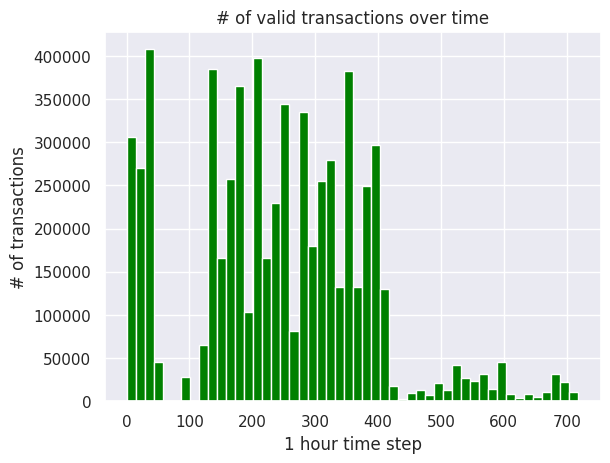

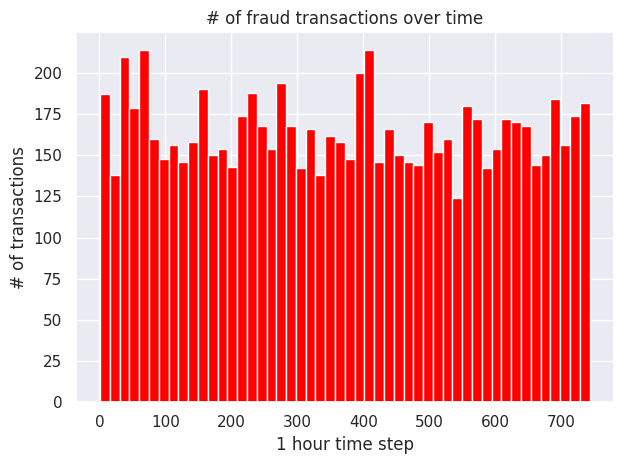

In [ ]:
bins = 50

valid.hist(column="step",color="green",bins=bins)
plt.xlabel("1 hour time step")
plt.ylabel("# of transactions")
plt.title("# of valid transactions over time")

fraud.hist(column ="step",color="red",bins=bins)
plt.xlabel("1 hour time step")
plt.ylabel("# of transactions")
plt.title("# of fraud transactions over time")

plt.tight_layout()
plt.show()

- A large proportion of valid transactions occur between around the 0th and 60th timestep as well as the 110th and 410th time-steps.
- The frequency at which fraudulent transactions occur does not seem to change much over time.

Let's see what the patterns look like over any particular, day of the week or hour of the day.

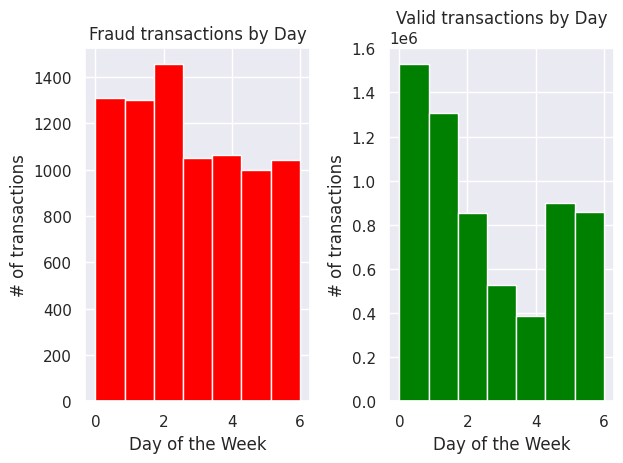

In [ ]:
num_days = 7
num_hours = 24
fraud_days = (fraud.step//num_hours)% num_days
fraud_hours = fraud.step % num_hours
valid_days = (valid.step//num_hours) % num_days
valid_hours = valid.step % num_hours

# plotting scatterplot of the days of the week, identifying the fraudulent transactions (red) from the valid transactions (green)
plt.subplot(1, 2, 1)
fraud_days.hist(bins=num_days,color="red")
plt.title('Fraud transactions by Day')
plt.xlabel('Day of the Week')
plt.ylabel("# of transactions")

plt.subplot(1,2,2)
valid_days.hist(bins=num_days,color="green")
plt.title('Valid transactions by Day')
plt.xlabel('Day of the Week')
plt.ylabel("# of transactions")

plt.tight_layout()
plt.show()

From the graphs above, there is little evidence to suggest that fraudulent transactions occur at particular days of the week.

While valid transactions occur less on some two consecutive days of the week.

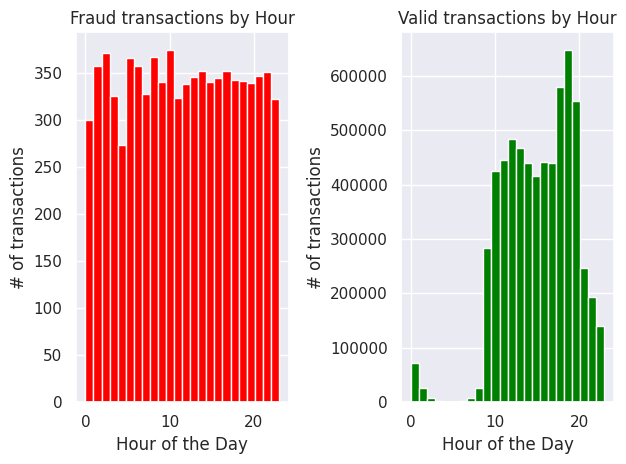

In [ ]:
plt.subplot(1, 2, 1)
fraud_hours.hist(bins=num_hours, color="red")
plt.title('Fraud transactions by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel("# of transactions")


plt.subplot(1, 2, 2)
valid_hours.hist(bins=num_hours, color="green")
plt.title('Valid transactions by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel("# of transactions")

plt.tight_layout()
plt.show()

We observe that from hour 0 to hour 9  valid transactions very seldom occur. On the other hand, fraudulent transactions still occur at similar rates to any hour of the day outside of hours 0 to 9 .

In response to this, We1m will create another feature HourOfDay, which is the step column with each number taken to modulo 24.

In [ ]:
data_new["HourOfDay"] = np.nan # initializing feature column
data_new.HourOfDay = data_new.step % 24


print("Head of dataset1: \n", pd.DataFrame.head(data_new))


Head of dataset1: 
    step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud Type2  \
0  M1979787155             0.0             0.0        0               0    CM   
1  M2044282225             0.0             0.0        0               0    CM   
2   C553264065             0.0             0.0        1               0    CC   
3    C38997010         21182.0             0.0        1               0    CC   
4  M1230701703             0.0             0.0        0               0    CM   

   HourOfDay  
0          1  
1          1

#### We will drop columns irrelevant for our modelling. These are isFlaggedFraud, nameOrig, nameDest columns.

In [ ]:
#data_new = data_new.drop(["isFlaggedFraud",'nameOrig','nameDest'],1)
data_new = data_new.drop(
    ["isFlaggedFraud", "nameOrig", "nameDest"],
    axis=1
)

### Pairplot of Variables

### Handling Categorical Variables

In [ ]:
data_new = pd.get_dummies(data_new,prefix=['type','Type2'],drop_first=True)

### Train-Test Split Standardizing Data

In [ ]:
X = data_new.drop("isFraud",axis=1)
y = data_new.isFraud

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Normalizing data so that all variables follow the same scale (0 to 1)
scaler = MinMaxScaler()

# Fit only to the training data
X_train=scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

## 1) Classification Models
Non-parametric machine learning methods may be preferred due to the large size of the data and that the goal is accurate classification, not interpretation

### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
clf = LogisticRegression()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_train)
CM_LR = confusion_matrix(y_test,y_pred)
CR_LR = classification_report(y_test,y_pred)
CM_LRtrain = confusion_matrix(y_train,y_predtrain)
CR_LRtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_LR)
print("Classification Report:\n",CR_LR)
print("Confusion Matrix Train:\n",CM_LRtrain)
print("Classification Report Train:\n",CR_LRtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test)[:, 1]))


Accuracy: 0.9987104368954928
Confusion Matrix:
 [[1270881       0]
 [   1641       2]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6567       3]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 1.0
Recall: 0.0012172854534388314
F1: 0.0024316109422492403


np.float64(0.06379366517662163)

### Bernoulli Naive Bayes

In [ ]:
clf = BernoulliNB()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_train)
CM_NB = confusion_matrix(y_test,y_pred)
CR_NB = classification_report(y_test,y_pred)
CM_NBtrain = confusion_matrix(y_train,y_predtrain)
CR_NBtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_NB)
print("Classification Report:\n",CR_NB)
print("Confusion Matrix Train:\n",CM_NBtrain)
print("Classification Report Train:\n",CR_NBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
average_precision_score(y_test, clf.predict_proba(X_test)[:, 1])

Accuracy: 0.9987096510556972
Confusion Matrix:
 [[1270881       0]
 [   1642       1]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6565       5]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 1.0
Recall: 0.0006086427267194157
F1: 0.0012165450121654502


np.float64(0.42640942298839657)

### Multinomial Naive Bayes

In [ ]:
clf = MultinomialNB()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_train)
CM_MNB = confusion_matrix(y_test,y_pred)
CR_MNB = classification_report(y_test,y_pred)
CM_MNBtrain = confusion_matrix(y_train,y_predtrain)
CR_MNBtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_MNB)
print("Classification Report:\n",CR_MNB)
print("Confusion Matrix Train:\n",CM_MNBtrain)
print("Classification Report Train:\n",CR_MNBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
average_precision_score(y_test, clf.predict_proba(X_test)[:, 1])

Accuracy: 0.9987088652159016
Confusion Matrix:
 [[1270881       0]
 [   1643       0]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6570       0]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       0.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       0.50      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.0
Recall: 0.0
F1: 0.0


np.float64(0.031969714459906984)

### Stochastic Gradient Classifier

In [ ]:
from sklearn.linear_model import SGDClassifier
clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
clf.fit(X_train, y_train)
y_pred=clf.predict(X_test)
y_predtrain=clf.predict(X_train)
SGDClassifier(max_iter=5)
CM_svc = confusion_matrix(y_test,y_pred)
CR_svc = classification_report(y_test,y_pred)
CM_svctrain = confusion_matrix(y_train,y_predtrain)
CR_svctrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_svc)
print("Classification Report:\n",CR_svc)
print("Confusion Matrix Train:\n",CM_svctrain)
print("Classification Report Train:\n",CR_svctrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
average_precision_score(y_test, clf.decision_function(X_test))

Accuracy: 0.9987088652159016
Confusion Matrix:
 [[1270881       0]
 [   1643       0]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6570       0]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       0.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       0.50      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.0
Recall: 0.0
F1: 0.0


np.float64(0.4693909233948882)

### RandomForestClassifier

A random forest is an algorithm that generates several decisions trees and pools the results of each tree to make a more robust prediction.

Another great thing about Random Forest is that We can assign weights to each class to reduced the bias of the model towards the majority class.

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,class_weight='balanced',n_jobs=-1)


RF.fit(X_train, y_train)

y_pred= RF.predict(X_test)
y_predtrain=RF.predict(X_train)

# Evaluating model
CM_RF_train=confusion_matrix(y_train,y_predtrain)
CR_RF_train= classification_report(y_train,y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
average_precision_score(y_test, RF.predict_proba(X_test)[:, 1])

Accuracy: 0.9997351719888976
Confusion Matrix:
 [[1270858      23]
 [    314    1329]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.81      0.89      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.90      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083525       1]
 [    102    6468]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.98      0.99      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.99      1.00   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.9829881656804734
Recall: 0.8088861838101035
F1: 0.8874791318864774


np.float64(0.9211180267115279)

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,n_jobs=-1)


RF.fit(X_train, y_train)

y_pred= RF.predict(X_test)
y_predtrain=RF.predict(X_train)

# Evaluating model
CM_RF_train=confusion_matrix(y_train,y_predtrain)
CR_RF_train= classification_report(y_train,y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
average_precision_score(y_test, RF.predict_proba(X_test)[:, 1])

Accuracy: 0.9997280994307377
Confusion Matrix:
 [[1270849      32]
 [    314    1329]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.81      0.88      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.90      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083524       2]
 [     91    6479]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.99      0.99      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.99      1.00   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.9764878765613519
Recall: 0.8088861838101035
F1: 0.8848202396804261


np.float64(0.9132821863979241)

### Observations and Conclusion

#### Confusion Matrix and Classification Report of RandomForest Classifier model

In [ ]:
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.81      0.88      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.90      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083524       2]
 [     91    6479]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.99      0.99      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.99      1.00   5090096
weighted avg       1.00      1.00      1.00   5090096



## 2) Classification Models (under sampling)

Non-parametric machine learning methods may be preferred due to the large size of the data and that the goal is accurate classification, not interpretation

### Performing Undersampling of Train Data
- **We undersample training data as when we trained classifiers with entire training data all classifiers except RandomForest and Neural Networks classified all points as non-Fraud and failed to detect any Fraud transaction**
- **Our training data is in millions so models will still learn train data well as the undersampled data will still contain enough number of transactions**

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(sampling_strategy=0.2)

In [ ]:
X_res, y_res = rus.fit_resample(X_train, y_train)

### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
clf = LogisticRegression()
clf.fit(X_res, y_res)

# Predictions
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_res)

# Evaluation
CM_LR = confusion_matrix(y_test, y_pred)
CR_LR = classification_report(y_test, y_pred)
CM_LRtrain = confusion_matrix(y_res, y_predtrain)
CR_LRtrain = classification_report(y_res, y_predtrain)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", CM_LR)
print("Classification Report:\n", CR_LR)
print("Confusion Matrix Train:\n", CM_LRtrain)
print("Classification Report Train:\n", CR_LRtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:",
      average_precision_score(y_test, clf.predict_proba(X_test)[:, 1]))

Accuracy: 0.9774110350767451
Confusion Matrix:
 [[1242840   28041]
 [    704     939]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99   1270881
           1       0.03      0.57      0.06      1643

    accuracy                           0.98   1272524
   macro avg       0.52      0.77      0.52   1272524
weighted avg       1.00      0.98      0.99   1272524

Confusion Matrix Train:
 [[32130   720]
 [ 2796  3774]]
Classification Report Train:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95     32850
           1       0.84      0.57      0.68      6570

    accuracy                           0.91     39420
   macro avg       0.88      0.78      0.82     39420
weighted avg       0.91      0.91      0.90     39420

Precision: 0.032401656314699795
Recall: 0.5715155203895314
F1: 0.06132645397250433
Area under precision (AUC) Recall: 0.22355673494085082


### Bernoulli Naive Bayes

In [ ]:
clf = BernoulliNB()
clf.fit(X_res, y_res)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_res)
CM_NB = confusion_matrix(y_test,y_pred)
CR_NB = classification_report(y_test,y_pred)
CM_NBtrain = confusion_matrix(y_res, y_predtrain)
CR_NBtrain = classification_report(y_res, y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_NB)
print("Classification Report:\n",CR_NB)
print("Confusion Matrix Train:\n",CM_NBtrain)
print("Classification Report Train:\n",CR_NBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, y_pred))

Accuracy: 0.9224006777082396
Confusion Matrix:
 [[1172692   98189]
 [    558    1085]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.92      0.96   1270881
           1       0.01      0.66      0.02      1643

    accuracy                           0.92   1272524
   macro avg       0.51      0.79      0.49   1272524
weighted avg       1.00      0.92      0.96   1272524

Confusion Matrix Train:
 [[30360  2490]
 [ 2362  4208]]
Classification Report Train:
               precision    recall  f1-score   support

           0       0.93      0.92      0.93     32850
           1       0.63      0.64      0.63      6570

    accuracy                           0.88     39420
   macro avg       0.78      0.78      0.78     39420
weighted avg       0.88      0.88      0.88     39420

Precision: 0.010929347059653082
Recall: 0.660377358490566
F1: 0.02150281914840909
Area under precision (AUC) Recall: 0.007655991947200539


### Multinomial Naive Bayes

In [ ]:
clf = MultinomialNB()
clf.fit(X_res, y_res)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_res)
CM_MNB = confusion_matrix(y_test,y_pred)
CR_MNB = classification_report(y_test,y_pred)
CM_MNBtrain = confusion_matrix(y_res, y_predtrain)
CR_MNBtrain = classification_report(y_res, y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_MNB)
print("Classification Report:\n",CR_MNB)
print("Confusion Matrix Train:\n",CM_MNBtrain)
print("Classification Report Train:\n",CR_MNBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, y_pred))

Accuracy: 0.916396075830397
Confusion Matrix:
 [[1165291  105590]
 [    798     845]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.92      0.96   1270881
           1       0.01      0.51      0.02      1643

    accuracy                           0.92   1272524
   macro avg       0.50      0.72      0.49   1272524
weighted avg       1.00      0.92      0.96   1272524

Confusion Matrix Train:
 [[30101  2749]
 [ 3320  3250]]
Classification Report Train:
               precision    recall  f1-score   support

           0       0.90      0.92      0.91     32850
           1       0.54      0.49      0.52      6570

    accuracy                           0.85     39420
   macro avg       0.72      0.71      0.71     39420
weighted avg       0.84      0.85      0.84     39420

Precision: 0.00793911777140978
Recall: 0.5143031040779062
F1: 0.015636854864079647
Area under precision (AUC) Recall: 0.0047102130703297425


### Stochastic Gradient Classifier

In [ ]:
from sklearn.linear_model import SGDClassifier
clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
clf.fit(X_res, y_res)
y_pred=clf.predict(X_test)
y_predtrain = clf.predict(X_res)
SGDClassifier(max_iter=5)
CM_svc = confusion_matrix(y_test,y_pred)
CR_svc = classification_report(y_test,y_pred)
CM_svctrain = confusion_matrix(y_res, y_predtrain)
CR_svctrain = classification_report(y_res, y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_svc)
print("Classification Report:\n",CR_svc)
print("Confusion Matrix Train:\n",CM_svctrain)
print("Classification Report Train:\n",CR_svctrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, y_pred))

Accuracy: 0.9758110652529932
Confusion Matrix:
 [[1240796   30085]
 [    696     947]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99   1270881
           1       0.03      0.58      0.06      1643

    accuracy                           0.98   1272524
   macro avg       0.51      0.78      0.52   1272524
weighted avg       1.00      0.98      0.99   1272524

Confusion Matrix Train:
 [[32102   748]
 [ 2735  3835]]
Classification Report Train:
               precision    recall  f1-score   support

           0       0.92      0.98      0.95     32850
           1       0.84      0.58      0.69      6570

    accuracy                           0.91     39420
   macro avg       0.88      0.78      0.82     39420
weighted avg       0.91      0.91      0.91     39420

Precision: 0.03051688579530807
Recall: 0.5763846622032867
F1: 0.05796480489671002
Area under precision (AUC) Recall: 0.018136409408331836


### RandomForestClassifier

A random forest is an algorithm that generates several decisions trees and pools the results of each tree to make a more robust prediction.

Another great thing about Random Forest is that We can assign weights to each class to reduced the bias of the model towards the majority class.

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,class_weight='balanced',n_jobs=-1)


RF.fit(X_train, y_train)

y_pred= RF.predict(X_test)
y_predtrain=RF.predict(X_train)

# Evaluating model
CM_RF_train=confusion_matrix(y_train,y_predtrain)
CR_RF_train= classification_report(y_train,y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, y_pred))

Accuracy: 0.9997280994307377
Confusion Matrix:
 [[1270852      29]
 [    317    1326]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.81      0.88      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.90      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083525       1]
 [     70    6500]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.99      0.99      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.99      1.00   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.9785977859778597
Recall: 0.8070602556299452
F1: 0.8845897264843229
Area under precision (AUC) Recall: 0.79003649052538

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,n_jobs=-1)


RF.fit(X_res, y_res)

y_pred= RF.predict(X_test)
y_predtrain = RF.predict(X_res)

# Evaluating model
CM_RF_train = confusion_matrix(y_res, y_predtrain)
CR_RF_train = classification_report(y_res, y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, y_pred))

Accuracy: 0.9958051871713225
Confusion Matrix:
 [[1265587    5294]
 [     44    1599]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.23      0.97      0.37      1643

    accuracy                           1.00   1272524
   macro avg       0.62      0.98      0.69   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[32849     1]
 [    1  6569]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     32850
           1       1.00      1.00      1.00      6570

    accuracy                           1.00     39420
   macro avg       1.00      1.00      1.00     39420
weighted avg       1.00      1.00      1.00     39420

Precision: 0.23197446685042797
Recall: 0.9732197200243458
F1: 0.3746485473289597
Area under precision (AUC) Recall: 0.22579670263197482


### Observations and Conclusion

#### Confusion Matrix and Classification Report of RandomForest Classifier model

In [ ]:
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.23      0.97      0.37      1643

    accuracy                           1.00   1272524
   macro avg       0.62      0.98      0.69   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[32849     1]
 [    1  6569]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     32850
           1       1.00      1.00      1.00      6570

    accuracy                           1.00     39420
   macro avg       1.00      1.00      1.00     39420
weighted avg       1.00      1.00      1.00     39420



## 3) Classification Models (over sampling)

Non-parametric machine learning methods may be preferred due to the large size of the data and that the goal is accurate classification, not interpretation

In [ ]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

# pip install imblearn (if you don't have imblearn in your system)
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state = 2)
X_res, y_res = sm.fit_resample(X_train, y_train.ravel())

print('After OverSampling, the shape of train_X: {}'.format(X_res.shape))
print('After OverSampling, the shape of train_y: {} \n'.format(y_res.shape))

print("After OverSampling, counts of label '1': {}".format(sum(y_res == 1)))
print("After OverSampling, counts of label '0': {}".format(sum(y_res == 0)))

Before OverSampling, counts of label '1': 6570
Before OverSampling, counts of label '0': 5083526 

After OverSampling, the shape of train_X: (10167052, 12)
After OverSampling, the shape of train_y: (10167052,) 

After OverSampling, counts of label '1': 5083526
After OverSampling, counts of label '0': 5083526


### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
clf = LogisticRegression()
clf.fit(X_res, y_res)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_res)
CM_LR = confusion_matrix(y_test,y_pred)
CR_LR = classification_report(y_test,y_pred)
CM_LRtrain = confusion_matrix(y_res, y_predtrain)
CR_LRtrain = classification_report(y_res, y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_LR)
print("Classification Report:\n",CR_LR)
print("Confusion Matrix Train:\n",CM_LRtrain)
print("Classification Report Train:\n",CR_LRtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test)[:, 1]))

Accuracy: 0.9433071596292093
Confusion Matrix:
 [[1198879   72002]
 [    141    1502]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.94      0.97   1270881
           1       0.02      0.91      0.04      1643

    accuracy                           0.94   1272524
   macro avg       0.51      0.93      0.51   1272524
weighted avg       1.00      0.94      0.97   1272524

Confusion Matrix Train:
 [[4795969  287557]
 [ 321244 4762282]]
Classification Report Train:
               precision    recall  f1-score   support

           0       0.94      0.94      0.94   5083526
           1       0.94      0.94      0.94   5083526

    accuracy                           0.94  10167052
   macro avg       0.94      0.94      0.94  10167052
weighted avg       0.94      0.94      0.94  10167052

Precision: 0.020434262080975187
Recall: 0.9141813755325624
F1: 0.039974982367892264
Area under precision (AUC) Recall: 0.34755493740564025


### Bernoulli Naive Bayes

In [ ]:
clf = BernoulliNB()
clf.fit(X_res, y_res)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_res)
CM_NB = confusion_matrix(y_test,y_pred)
CR_NB = classification_report(y_test,y_pred)
CM_NBtrain = confusion_matrix(y_res, y_predtrain)
CR_NBtrain = classification_report(y_res, y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_NB)
print("Classification Report:\n",CR_NB)
print("Confusion Matrix Train:\n",CM_NBtrain)
print("Classification Report Train:\n",CR_NBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test)[:, 1]))

Accuracy: 0.8146361090242699
Confusion Matrix:
 [[1035004  235877]
 [      3    1640]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.81      0.90   1270881
           1       0.01      1.00      0.01      1643

    accuracy                           0.81   1272524
   macro avg       0.50      0.91      0.46   1272524
weighted avg       1.00      0.81      0.90   1272524

Confusion Matrix Train:
 [[4138960  944566]
 [   3662 5079864]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      0.81      0.90   5083526
           1       0.84      1.00      0.91   5083526

    accuracy                           0.91  10167052
   macro avg       0.92      0.91      0.91  10167052
weighted avg       0.92      0.91      0.91  10167052

Precision: 0.0069047689218034915
Recall: 0.9981740718198417
F1: 0.013714668004683057
Area under precision (AUC) Recall: 0.33444273807684866


### Multinomial Naive Bayes

In [ ]:
clf = MultinomialNB()
clf.fit(X_res, y_res)
y_pred = clf.predict(X_test)
y_predtrain = clf.predict(X_train)
CM_MNB = confusion_matrix(y_test,y_pred)
CR_MNB = classification_report(y_test,y_pred)
CM_MNBtrain = confusion_matrix(y_train,y_predtrain)
CR_MNBtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_MNB)
print("Classification Report:\n",CR_MNB)
print("Confusion Matrix Train:\n",CM_MNBtrain)
print("Classification Report Train:\n",CR_MNBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test)[:, 1]))

Accuracy: 0.4985564122955638
Confusion Matrix:
 [[632782 638099]
 [     0   1643]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.50      0.66   1270881
           1       0.00      1.00      0.01      1643

    accuracy                           0.50   1272524
   macro avg       0.50      0.75      0.33   1272524
weighted avg       1.00      0.50      0.66   1272524

Confusion Matrix Train:
 [[2530223 2553303]
 [      0    6570]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      0.50      0.66   5083526
           1       0.00      1.00      0.01      6570

    accuracy                           0.50   5090096
   macro avg       0.50      0.75      0.33   5090096
weighted avg       1.00      0.50      0.66   5090096

Precision: 0.002568222814822225
Recall: 1.0
F1: 0.005123287884811775
Area under precision (AUC) Recall: 0.03490152711190892


### Stochastic Gradient Classifier

In [ ]:
from sklearn.linear_model import SGDClassifier
clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
clf.fit(X_res, y_res)
y_pred=clf.predict(X_test)
y_predtrain=clf.predict(X_train)
SGDClassifier(max_iter=5)
CM_svc = confusion_matrix(y_test,y_pred)
CR_svc = classification_report(y_test,y_pred)
CM_svctrain = confusion_matrix(y_train,y_predtrain)
CR_svctrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_svc)
print("Classification Report:\n",CR_svc)
print("Confusion Matrix Train:\n",CM_svctrain)
print("Classification Report Train:\n",CR_svctrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.decision_function(X_test)))

Accuracy: 0.8370710493475958
Confusion Matrix:
 [[1063788  207093]
 [    238    1405]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.84      0.91   1270881
           1       0.01      0.86      0.01      1643

    accuracy                           0.84   1272524
   macro avg       0.50      0.85      0.46   1272524
weighted avg       1.00      0.84      0.91   1272524

Confusion Matrix Train:
 [[4255047  828479]
 [    911    5659]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      0.84      0.91   5083526
           1       0.01      0.86      0.01      6570

    accuracy                           0.84   5090096
   macro avg       0.50      0.85      0.46   5090096
weighted avg       1.00      0.84      0.91   5090096

Precision: 0.006738673752266209
Recall: 0.855143031040779
F1: 0.013371974055515106
Area under precision (AUC) Recall: 0.17705279044235736


### RandomForestClassifier

A random forest is an algorithm that generates several decisions trees and pools the results of each tree to make a more robust prediction.

Another great thing about Random Forest is that We can assign weights to each class to reduced the bias of the model towards the majority class.

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,class_weight='balanced',n_jobs=-1)


RF.fit(X_train, y_train)

y_pred= RF.predict(X_test)
y_predtrain=RF.predict(X_train)

# Evaluating model
CM_RF_train=confusion_matrix(y_train,y_predtrain)
CR_RF_train= classification_report(y_train,y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, RF.predict_proba(X_test)[:, 1]))

Accuracy: 0.9997351719888976
Confusion Matrix:
 [[1270861      20]
 [    317    1326]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.99      0.81      0.89      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.90      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083525       1]
 [     84    6486]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.99      0.99      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.99      1.00   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.9851411589895989
Recall: 0.8070602556299452
F1: 0.8872532619605219
Area under precision (AUC) Recall: 0.91425610346225

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,n_jobs=-1)


RF.fit(X_res, y_res)

y_pred= RF.predict(X_test)
y_predtrain = RF.predict(X_res)

# Evaluating model
CM_RF_train = confusion_matrix(y_res, y_predtrain)
CR_RF_train = classification_report(y_res, y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, RF.predict_proba(X_test)[:, 1]))

Accuracy: 0.9989108260433595
Confusion Matrix:
 [[1269545    1336]
 [     50    1593]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.54      0.97      0.70      1643

    accuracy                           1.00   1272524
   macro avg       0.77      0.98      0.85   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083368     158]
 [      8 5083518]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      1.00      1.00   5083526

    accuracy                           1.00  10167052
   macro avg       1.00      1.00      1.00  10167052
weighted avg       1.00      1.00      1.00  10167052

Precision: 0.5438716285421645
Recall: 0.9695678636640293
F1: 0.6968503937007874
Area under precision (AUC) Recall: 0.91774400193602

### Observations and Conclusion

#### Confusion Matrix and Classification Report of RandomForest Classifier model

In [ ]:
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.54      0.97      0.70      1643

    accuracy                           1.00   1272524
   macro avg       0.77      0.98      0.85   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083368     158]
 [      8 5083518]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      1.00      1.00   5083526

    accuracy                           1.00  10167052
   macro avg       1.00      1.00      1.00  10167052
weighted avg       1.00      1.00      1.00  10167052



## 4) Classification Models with dimension reduction(PCA)

Non-parametric machine learning methods may be preferred due to the large size of the data and that the goal is accurate classification, not interpretation

In [ ]:
# Applying PCA function on training
# and testing set of X component
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_train_decomposed = pca.fit_transform(X_train)
X_test_decomposed = pca.transform(X_test)


### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
clf = LogisticRegression()
clf.fit(X_train_decomposed, y_train)
y_pred = clf.predict(X_test_decomposed)
y_predtrain = clf.predict(X_train_decomposed)
CM_LR = confusion_matrix(y_test,y_pred)
CR_LR = classification_report(y_test,y_pred)
CM_LRtrain = confusion_matrix(y_train,y_predtrain)
CR_LRtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_LR)
print("Classification Report:\n",CR_LR)
print("Confusion Matrix Train:\n",CM_LRtrain)
print("Classification Report Train:\n",CR_LRtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test_decomposed)[:, 1]))

Accuracy: 0.9987088652159016
Confusion Matrix:
 [[1270881       0]
 [   1643       0]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6570       0]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       0.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       0.50      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.0
Recall: 0.0
F1: 0.0
Area under precision (AUC) Recall: 0.06993035818765674


### Bernoulli Naive Bayes

In [ ]:
clf = BernoulliNB()
clf.fit(X_train_decomposed, y_train)
y_pred = clf.predict(X_test_decomposed)
y_predtrain = clf.predict(X_train_decomposed)
CM_NB = confusion_matrix(y_test,y_pred)
CR_NB = classification_report(y_test,y_pred)
CM_NBtrain = confusion_matrix(y_train,y_predtrain)
CR_NBtrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_NB)
print("Classification Report:\n",CR_NB)
print("Confusion Matrix Train:\n",CM_NBtrain)
print("Classification Report Train:\n",CR_NBtrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.predict_proba(X_test_decomposed)[:, 1]))

Accuracy: 0.9987088652159016
Confusion Matrix:
 [[1270881       0]
 [   1643       0]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6570       0]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       0.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       0.50      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.0
Recall: 0.0
F1: 0.0
Area under precision (AUC) Recall: 0.002047470623207452


### Stochastic Gradient Classifier

In [ ]:
from sklearn.linear_model import SGDClassifier
clf = SGDClassifier(loss="hinge", penalty="l2", max_iter=5)
clf.fit(X_train_decomposed, y_train)
y_pred = clf.predict(X_test_decomposed)
y_predtrain=clf.predict(X_train_decomposed)
SGDClassifier(max_iter=5)
CM_svc = confusion_matrix(y_test,y_pred)
CR_svc = classification_report(y_test,y_pred)
CM_svctrain = confusion_matrix(y_train,y_predtrain)
CR_svctrain = classification_report(y_train,y_predtrain)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_svc)
print("Classification Report:\n",CR_svc)
print("Confusion Matrix Train:\n",CM_svctrain)
print("Classification Report Train:\n",CR_svctrain)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.decision_function(X_test_decomposed)))

Accuracy: 0.9987088652159016
Confusion Matrix:
 [[1270881       0]
 [   1643       0]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train:
 [[5083526       0]
 [   6570       0]]
Classification Report Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       0.00      0.00      0.00      6570

    accuracy                           1.00   5090096
   macro avg       0.50      0.50      0.50   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.0
Recall: 0.0
F1: 0.0
Area under precision (AUC) Recall: 0.05973652847744809


### RandomForestClassifier

A random forest is an algorithm that generates several decisions trees and pools the results of each tree to make a more robust prediction.

Another great thing about Random Forest is that We can assign weights to each class to reduced the bias of the model towards the majority class.

In [ ]:
RF = RandomForestClassifier(n_estimators=15,oob_score=True,class_weight='balanced',n_jobs=-1)


RF.fit(X_train_decomposed, y_train)

y_pred = RF.predict(X_test_decomposed)
y_predtrain=RF.predict(X_train_decomposed)

# Evaluating model
CM_RF_train=confusion_matrix(y_train,y_predtrain)
CR_RF_train= classification_report(y_train,y_predtrain)
CM_RF = confusion_matrix(y_test,y_pred)
CR_RF = classification_report(y_test,y_pred)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n",CM_RF)
print("Classification Report:\n",CR_RF)
print("Confusion Matrix Train Data:\n",CM_RF_train)
print("Classification Report Train Data:\n",CR_RF_train)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("Area under precision (AUC) Recall:", average_precision_score(y_test, clf.decision_function(X_test_decomposed)))

Accuracy: 0.9988149535883016
Confusion Matrix:
 [[1270691     190]
 [   1318     325]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.63      0.20      0.30      1643

    accuracy                           1.00   1272524
   macro avg       0.82      0.60      0.65   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix Train Data:
 [[5083505      21]
 [    531    6039]]
Classification Report Train Data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.92      0.96      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.96      0.98   5090096
weighted avg       1.00      1.00      1.00   5090096

Precision: 0.6310679611650486
Recall: 0.1978088861838101
F1: 0.30120481927710846
Area under precision (AUC) Recall: 0.0548509309064

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

RF = RandomForestClassifier(
    n_estimators=5,
    n_jobs=2,
    random_state=42
)

RF.fit(X_train_decomposed, y_train)

y_pred = RF.predict(X_test_decomposed)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[1270523     358]
 [   1264     379]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.51      0.23      0.32      1643

    accuracy                           1.00   1272524
   macro avg       0.76      0.62      0.66   1272524
weighted avg       1.00      1.00      1.00   1272524



## 5) KMeans

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
# Determine the optimal number of clusters using the Elbow Method
inertia = []
K = range(1, 10)  # Test for clusters from 1 to 10
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_train)
    inertia.append(kmeans.inertia_)

In [ ]:
print('inertia: ', inertia)

inertia:  [4260476.400886585, 1640820.9330042615, 736416.0477251417, 422195.15718500287, 372460.2271896355, 345339.07180105726, 334945.58196256374, 287689.7350241372, 269982.9930767894]


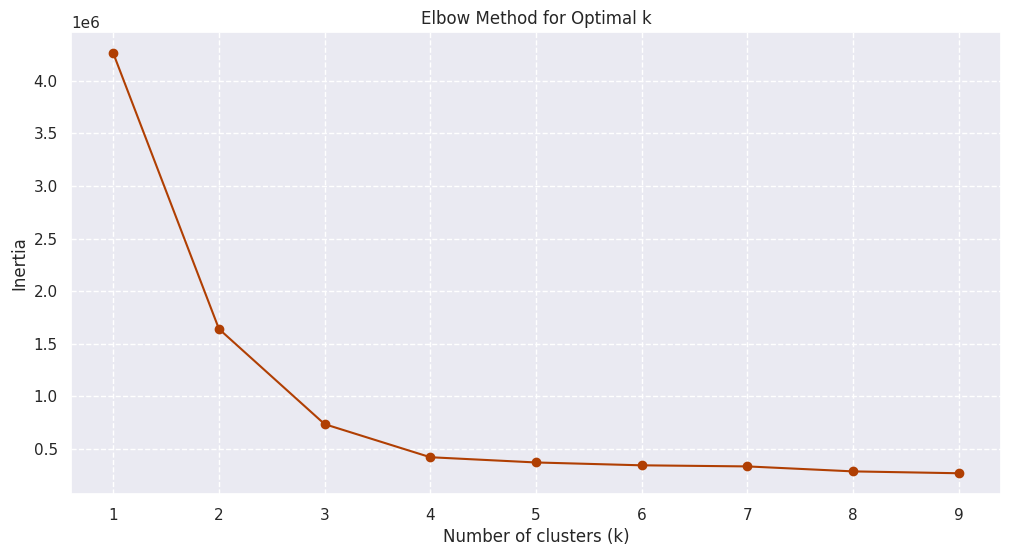

In [ ]:
# Plot the Elbow Method
plt.figure(figsize=(12, 6))
plt.plot(K, inertia, marker='o', linestyle='-', color=sns.color_palette("YlOrBr", 10)[8])
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True, linestyle='--')
plt.show()

In [ ]:

# Fit K-means with the chosen number of clusters (k=3)
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
kmeans.fit(X_train)

# Assign clusters and calculate distance to cluster centroid
train_data = data.iloc[:len(X_train)].copy()
train_data['Cluster'] = kmeans.labels_

train_data['DistanceToCentroid'] = np.linalg.norm(
    X_train - kmeans.cluster_centers_[kmeans.labels_],
    axis=1
)

# Identify potential frauds based on distance threshold
threshold = train_data['DistanceToCentroid'].quantile(0.95)
potential_frauds = train_data[
    train_data['DistanceToCentroid'] > threshold
]

print(f"Number of potential frauds detected: {len(potential_frauds)}")
display(potential_frauds)


Number of potential frauds detected: 254505


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,Cluster,DistanceToCentroid
18,1,PAYMENT,671.64,C2033524545,15123.00,14451.36,M473053293,0.00,0.00,0,0,1,0.784947
26,1,PAYMENT,9478.39,C1671590089,116494.00,107015.61,M58488213,0.00,0.00,0,0,1,0.804519
41,1,DEBIT,5758.59,C1466917878,32604.00,26845.41,C1297685781,209699.00,16997.22,0,0,1,0.783559
55,1,PAYMENT,2970.97,C46941357,38071.06,35100.09,M1152606315,0.00,0.00,0,0,1,0.784190
90,1,TRANSFER,358831.92,C908084672,0.00,0.00,C392292416,474384.53,3420103.09,0,0,1,1.004043
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5089935,355,CASH_IN,169973.82,C499025110,20488.00,190461.82,C1071355290,86669.67,9387.13,0,0,1,0.803798
5090015,355,CASH_OUT,1444.19,C440961818,199111.00,197666.81,C654703535,0.00,1444.19,0,0,1,1.048072
5090042,355,TRANSFER,331519.71,C1447538877,0.00,0.00,C1285953370,1258875.07,1590394.78,0,0,1,0.803163
5090057,355,TRANSFER,124928.54,C1700667685,0.00,0.00,C2030046412,448611.16,573539.70,0,0,1,0.830907


In [ ]:

import numpy as np
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)


rng = np.random.RandomState(42)
sample_size = min(10000, len(X_train))
idx = rng.choice(len(X_train), size=sample_size, replace=False)

X_sample = X_train[idx]
clusters_sample = kmeans.labels_[idx]


y_array = np.asarray(y_train).ravel()
y_sample = y_array[idx]

# 1. Silhouette Score
silhouette = silhouette_score(X_sample, clusters_sample)
print("Silhouette Score:", silhouette)

# 2. Adjusted Rand Index
ari = adjusted_rand_score(y_sample, clusters_sample)
print("Adjusted Rand Index:", ari)

# 3. Normalized Mutual Information
nmi = normalized_mutual_info_score(y_sample, clusters_sample)
print("Normalized Mutual Information:", nmi)

# 4. Cluster sizes
print("\nCluster sizes:")
print(np.unique(kmeans.labels_, return_counts=True))

# 5. Fraud distribution in each cluster
print("\nFraud distribution in each cluster:")
for cluster in np.unique(kmeans.labels_):
    mask = (kmeans.labels_ == cluster)
    print(f"\nCluster {cluster}:")
    print("Total samples:", mask.sum())
    print("Actual frauds:", int(y_array[mask].sum()))
    print("Fraud percentage:", round(y_array[mask].mean() * 100, 4), "%")


Silhouette Score: 0.6589314412219736
Adjusted Rand Index: -5.943578600823606e-05
Normalized Mutual Information: 0.0006503595591021865

Cluster sizes:
(array([0, 1, 2], dtype=int32), array([1721234, 1578555, 1790307]))

Fraud distribution in each cluster:

Cluster 0:
Total samples: 1721234
Actual frauds: 0
Fraud percentage: 0.0 %

Cluster 1:
Total samples: 1578555
Actual frauds: 3252
Fraud percentage: 0.206 %

Cluster 2:
Total samples: 1790307
Actual frauds: 3318
Fraud percentage: 0.1853 %


## 6) Isolation Forest

![iso](https://machinelearninggeek.com/wp-content/uploads/2020/10/image-78.png)

Image taken from [here](https://machinelearninggeek.com/outlier-detection-using-isolation-forests/).

<div style="border: 2px solid #00777F; padding: 15px; border-radius: 10px;">
    <p style="font-size: 16px">
        <strong>🌲 Isolation Forest</strong>: This technique works by randomly selecting features and splitting data points. Anomalies, or outliers, are easier to isolate, resulting in shorter paths in the "forest." It's effective for large datasets, as it can quickly identify anomalies without needing to model the data's distribution. However, it may miss complex patterns since it relies on simple random splits.
    </p>
</div>

In [ ]:
from sklearn.ensemble import IsolationForest

In [ ]:
# Initialize the Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=101)   # high contamination to catch more fraud transactions

# Fit the model and predict (returns -1 for anomalies and 1 for normal data)
iso_preds = iso_forest.fit_predict(X_train)

# Convert -1 (anomalies) to 1 (fraud) and 1 (normal) to 0 (non-fraud)
iso_preds = [1 if x == -1 else 0 for x in iso_preds]

# Evaluate the results
print(classification_report(y_train, iso_preds))
roc_auc = roc_auc_score(y_train, iso_preds)
print("ROC AUC Score: ", roc_auc)

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   5083526
           1       0.01      0.42      0.02      6570

    accuracy                           0.95   5090096
   macro avg       0.51      0.69      0.50   5090096
weighted avg       1.00      0.95      0.97   5090096

ROC AUC Score:  0.6873422474567354


In [ ]:
from matplotlib.colors import LinearSegmentedColormap

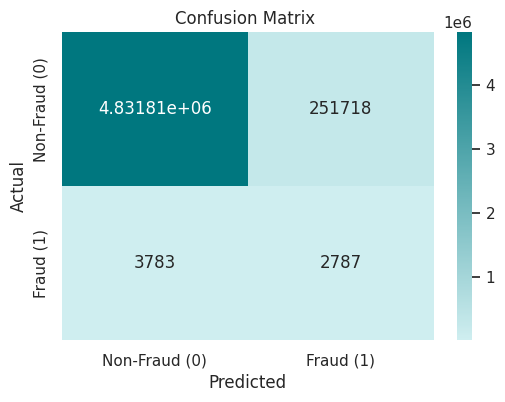

In [ ]:
# Custom color palette
colors = ['#CFEEF0', '#00777F']
custom_cmap = LinearSegmentedColormap.from_list('custom_cmap', colors)

# Plot the confusion matrix
cm = confusion_matrix(y_train, iso_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, cmap=custom_cmap, fmt='g')

# Add labels, title, and axis ticks
plt.title('Confusion Matrix ')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks([0.5, 1.5], ['Non-Fraud (0)', 'Fraud (1)'])
plt.yticks([0.5, 1.5], ['Non-Fraud (0)', 'Fraud (1)'])
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Continuous anomaly scores
y_scores = -iso_forest.score_samples(X_train)

print("ROC-AUC:", roc_auc_score(y_train, y_scores))
print("Average Precision:", average_precision_score(y_train, y_scores))

ROC-AUC: 0.8561616665899896
Average Precision: 0.009267806662596835


In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = []

for contamination in [0.001, 0.005, 0.01, 0.05]:
    model = IsolationForest(
        contamination=contamination,
        random_state=101,
        n_jobs=-1
    )

    preds = model.fit_predict(X_train)
    preds = (preds == -1).astype(int)

    results.append({
        "Contamination": contamination,
        "Precision": precision_score(y_train, preds, zero_division=0),
        "Recall": recall_score(y_train, preds, zero_division=0),
        "F1": f1_score(y_train, preds, zero_division=0),
        "Predicted Anomalies": int(preds.sum())
    })

results_df = pd.DataFrame(results)
display(results_df)

,Contamination,Precision,Recall,F1,Predicted Anomalies
0,0.001,0.014937,0.011568,0.013038,5088
1,0.005,0.016345,0.063318,0.025983,25451
2,0.010,0.013595,0.105327,0.024082,50901
3,0.050,0.010951,0.424201,0.021350,254505


In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

iso_forest = IsolationForest(
    contamination=0.005,
    random_state=101,
    n_jobs=-1
)

iso_forest.fit(X_train)

# Evaluation
test_scores = -iso_forest.score_samples(X_test)
threshold = -iso_forest.offset_
iso_test_preds = (test_scores >= threshold).astype(int)

print(classification_report(y_test, iso_test_preds, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, iso_test_preds))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.01      0.06      0.02      1643

    accuracy                           0.99   1272524
   macro avg       0.51      0.53      0.51   1272524
weighted avg       1.00      0.99      1.00   1272524

Confusion Matrix:
[[1264695    6186]
 [   1549      94]]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.percentile(test_scores, [99, 99.5, 99.9, 99.95, 99.99])

results = []

for threshold in thresholds:
    preds = (test_scores >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "Predicted Anomalies": int(preds.sum())
    })

results_df = pd.DataFrame(results)
display(results_df)

,Threshold,Precision,Recall,F1,Predicted Anomalies
0,0.619782,0.013830,0.107121,0.024497,12726
1,0.640465,0.015399,0.059647,0.024479,6364
2,0.688148,0.016496,0.012781,0.014403,1273
3,0.704580,0.015699,0.006086,0.008772,637
4,0.723806,0.030769,0.002435,0.004512,130


# Final Results & Conclusion

## 1. Supervised Classification Results

### Original Training Data

| Model | Precision | Recall | F1-score | Average Precision |
|---|---:|---:|---:|---:|
| Logistic Regression | 1.0000 | 0.0012 | 0.0024 | 0.0638 |
| Bernoulli Naive Bayes | 1.0000 | 0.0006 | 0.0012 | 0.4264 |
| Multinomial Naive Bayes | 0.0000 | 0.0000 | 0.0000 | 0.0320 |
| SGD (Hinge Loss) | 0.0000 | 0.0000 | 0.0000 | 0.4694 |
| Random Forest (Without Class Weight) | 0.9765 | 0.8089 | 0.8848 | 0.9133 |
| Random Forest (Class Weight = Balanced) | 0.9786 | 0.8071 | 0.8846 | Not recorded |

*Note: Average Precision values for Logistic Regression, BernoulliNB, MultinomialNB, SGD, and Random Forest without class weighting were calculated from continuous prediction scores. The class-weighted Random Forest Average Precision was not reliably recorded.*

### Random Undersampling

| Model | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Logistic Regression | 0.0324 | 0.5715 | 0.0613 |
| Bernoulli Naive Bayes | 0.0109 | 0.6604 | 0.0215 |
| Multinomial Naive Bayes | 0.0079 | 0.5143 | 0.0156 |
| SGD (Hinge Loss) | 0.0305 | 0.5764 | 0.0580 |
| Random Forest | 0.2320 | 0.9732 | 0.3746 |

### SMOTE Oversampling

| Model | Precision | Recall | F1-score | Average Precision |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.0204 | 0.9142 | 0.0400 | 0.3476 |
| Bernoulli Naive Bayes | 0.0069 | 0.9982 | 0.0137 | Not recorded |
| Multinomial Naive Bayes | 0.0026 | 1.0000 | 0.0051 | Not recorded |
| SGD (Hinge Loss) | 0.0067 | 0.8551 | 0.0134 | Not recorded |
| Random Forest | 0.5439 | 0.9696 | 0.6969 | 0.9177 |

*Note: Average Precision values are included only where reliable continuous-score results were recorded. Other values are omitted rather than estimated.*

## 2. Dimensionality Reduction Results

PCA was applied with two principal components.

| Model | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Random Forest | 0.6311 | 0.1978 | 0.3012 |

The two-component PCA representation considerably reduced Random Forest's fraud detection performance, suggesting that important information for distinguishing fraudulent transactions was lost during dimensionality reduction.

## 3. Unsupervised Learning Results

### K-Means Clustering

| Metric | Result |
|---|---:|
| Number of Clusters | 3 |
| Silhouette Score | 0.6589 |
| Adjusted Rand Index (ARI) | -0.00006 |
| Normalized Mutual Information (NMI) | 0.00065 |

K-Means produced reasonably separated clusters in the feature space, but the very low ARI and NMI values indicate almost no agreement between the discovered clusters and the actual fraud labels.

### Isolation Forest

| Evaluation | Result |
|---|---:|
| Training ROC-AUC | 0.8562 |
| Training Average Precision | 0.0093 |
| Test Precision | 0.0150 |
| Test Recall | 0.0572 |
| Test F1-score | 0.0225 |

Isolation Forest was also evaluated with different contamination rates and decision thresholds. Although it showed some ability to rank unusual transactions, its test results indicated poor performance as a standalone fraud detection method.

## 4. Final Conclusion

- Random Forest trained on the original dataset with class weighting achieved the strongest overall balance between precision and recall among the tested classification strategies.
- Random undersampling and SMOTE increased fraud recall but resulted in more false positive predictions.
- Logistic Regression, Naive Bayes, and SGD struggled to identify fraudulent transactions when trained on the original imbalanced dataset.
- PCA with two components reduced Random Forest performance considerably.
- K-Means identified general transaction patterns but did not produce clusters that aligned with fraud labels.
- Isolation Forest demonstrated the limitations of unsupervised anomaly detection for directly identifying fraudulent transactions in this experiment.

Overall, the experiments highlight the importance of handling class imbalance and selecting appropriate evaluation metrics for highly imbalanced fraud detection problems.